In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import scipy.sparse as sps
import jlinops




# from solvers import GKSIAS
# from psolvers import PGKSIAS
# from rsolvers import RIASGKS

from msolver import MMGKS

# Setup toy problem

In [3]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect") # was 10
#A = jlinops.IdentityOperator((n,n))
b = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

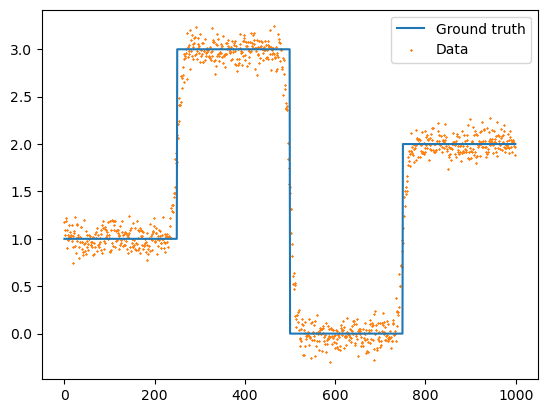

In [4]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, b, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization

In [5]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Set parameters

In [43]:
n_iters = 200
q = 1.0
epsilon = 1e-2
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [44]:
# Set method
method = "dp"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)


err_norm_sq = len(b) # in expectation

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# # Run the solver
# ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


In [106]:
data = mmgks_solver.solve(n_iter=200, init_dim=5, x0=None, lambdah0=None,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=200, init_dim=5, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

generating basis...: 100%|██████████| 5/5 [00:00<00:00, 1331.86it/s]


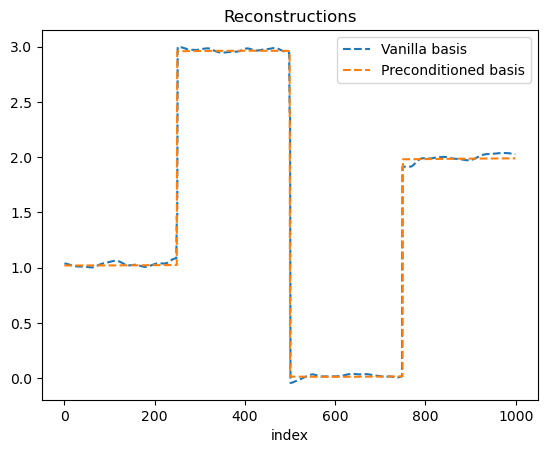

In [107]:
plt.plot(data['x'], label="Vanilla basis", ls="--")
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
# plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

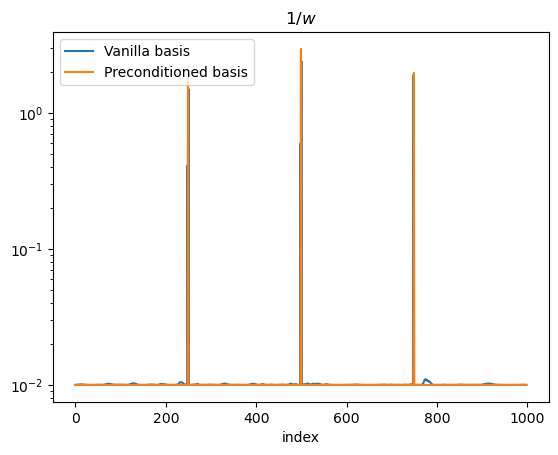

In [108]:
plt.semilogy(1.0/data['w'], label="Vanilla basis")
plt.semilogy(1.0/pdata['w'], label="Preconditioned basis")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

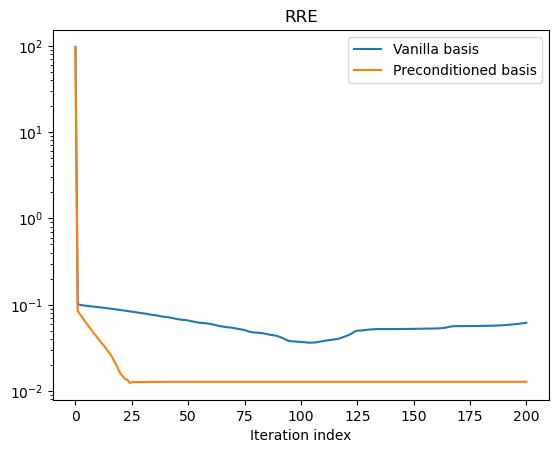

In [109]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

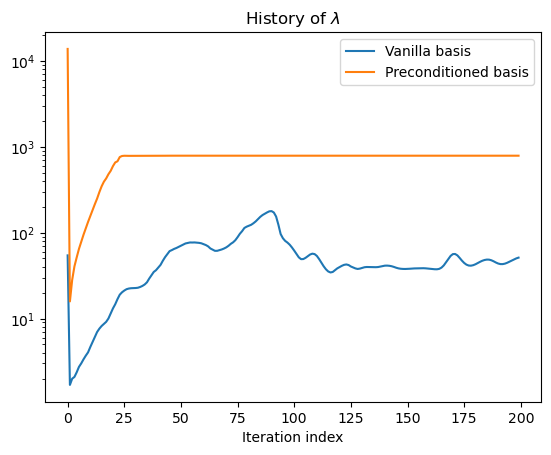

In [110]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

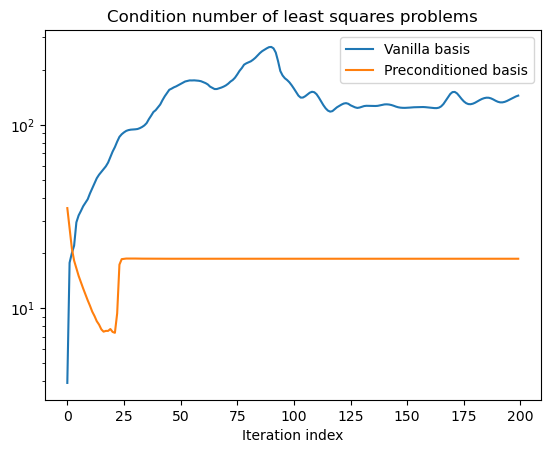

In [111]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# IAS solve

In [6]:
# Set method
method = "dp2"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = jlinops.MatrixLinearOperator(Wmat)


Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*b

err_norm_sq = len(b) # in expectation

# Build solver
ias_solver = GKSIAS(A, L, b, noise_var=noise_var)

# Run the solver
ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


# 

In [7]:
# Set method
method = "dp2"


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = jlinops.MatrixLinearOperator(Wmat)


Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*b

err_norm_sq = len(b) # in expectation

pias_data = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=8, n_iter=n_iters, regparam=method, x_true=ground_truth, x0=None, shift_scale=1.0, regparam_fixed=1e0,
                           err_norm_sq=err_norm_sq)

running MMGKS...: 100%|██████████| 200/200 [02:12<00:00,  1.51it/s]


# RIAS

In [8]:
n_iters = 1000

kmin = 15
kmax = 30

# Set method
method = "dp2"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = jlinops.MatrixLinearOperator(Wmat)


Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*b

err_norm_sq = len(b) # in expectation

rias_solver = RIASGKS(A, L, b, noise_var=noise_var)

rias_data = rias_solver.solve(n_iter=n_iters, kmin=kmin, kmax=kmax, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)

# Comparison

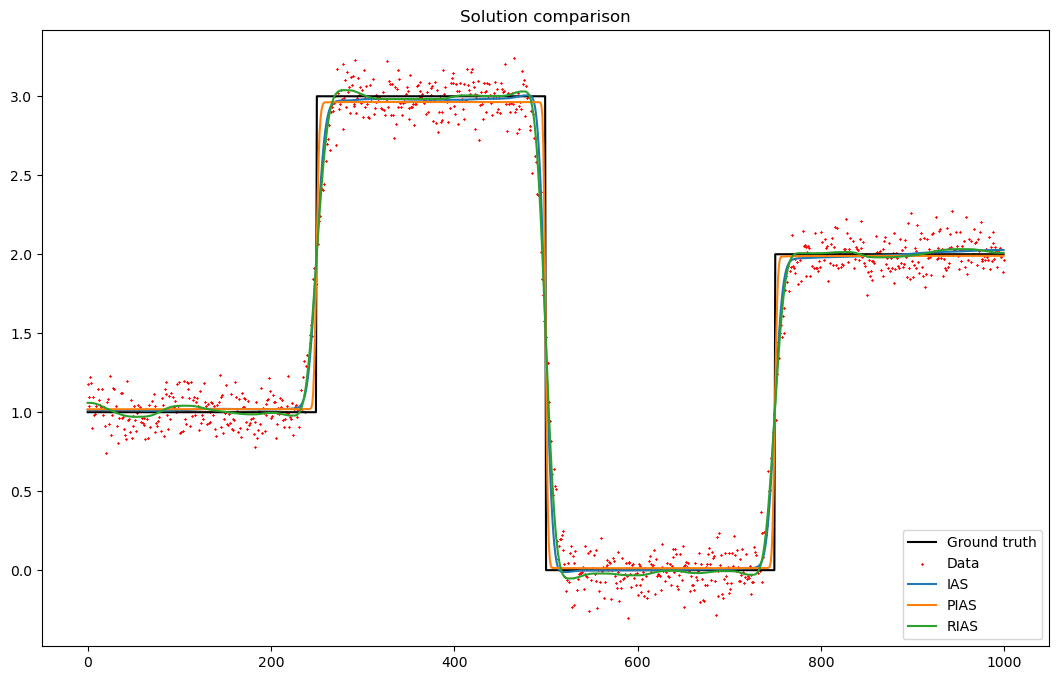

In [9]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, b, marker="x", label="Data", color="red", alpha=1.0, s=0.5)


plt.plot(grid, ias_data["x"], label="IAS")
plt.plot(grid, pias_data[0], label="PIAS")
plt.plot(grid, rias_data["x"], label="RIAS")


plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

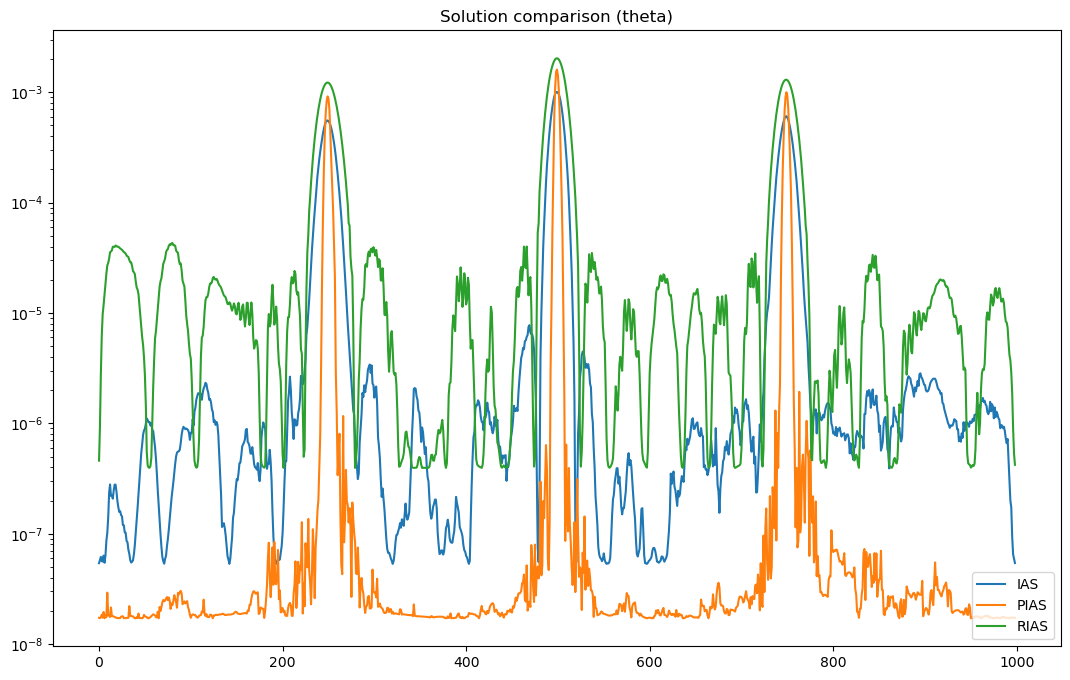

In [10]:
plt.figure(figsize=(13,8))

plt.semilogy(grid[:-1], ias_data["theta"], label="IAS")
plt.semilogy(grid[:-1], pias_data[1]["theta"], label="PIAS")
plt.semilogy(grid[:-1], rias_data["theta"], label="RIAS")

plt.legend(loc="lower right")
plt.title("Solution comparison (theta)")
plt.show()

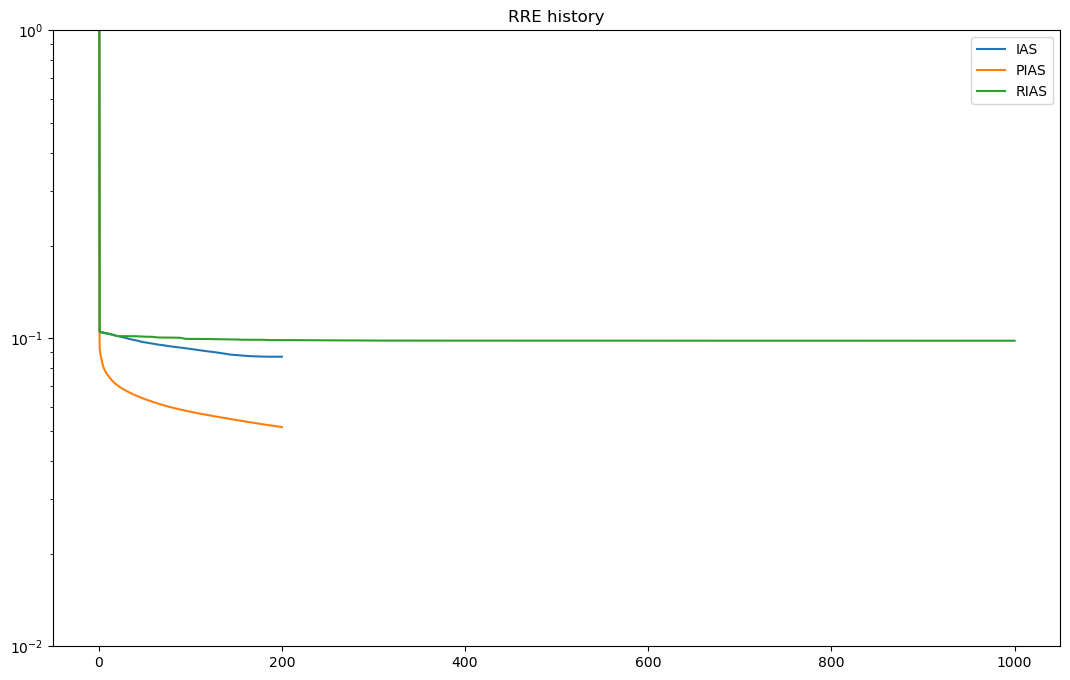

In [11]:
plt.figure(figsize=(13,8))

plt.semilogy(ias_data["rre_history"], label="IAS")
plt.semilogy(pias_data[1]["relError"], label="PIAS")
plt.semilogy(rias_data["rre_history"], label="RIAS")

plt.legend(loc="upper right")
plt.title("RRE history")
plt.ylim(1e-2, 1e-0)
plt.show()

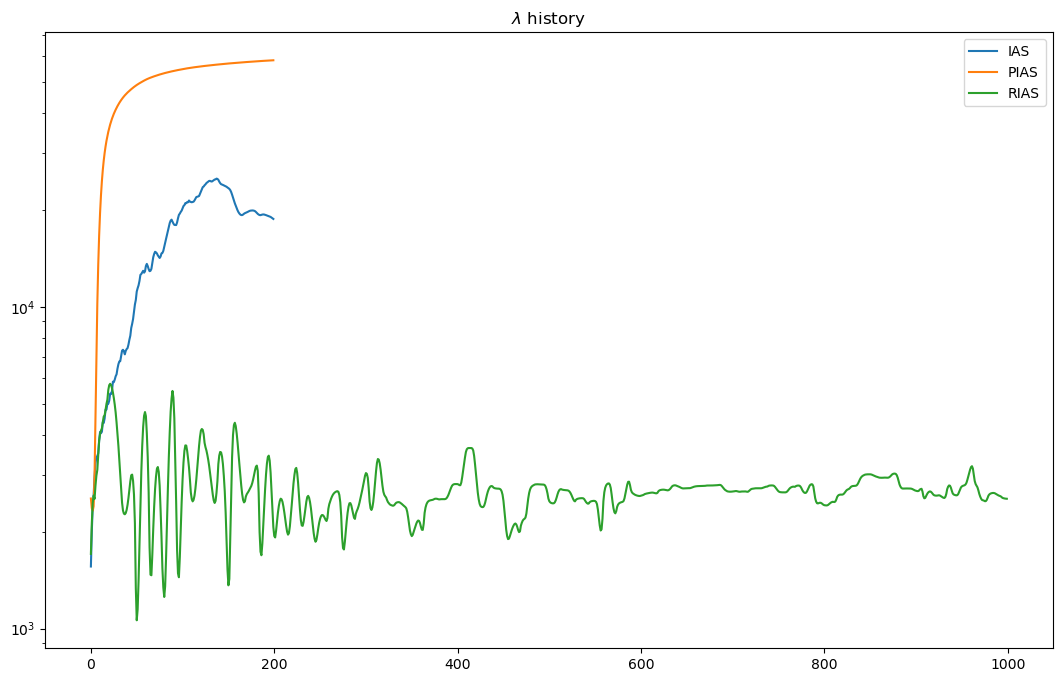

In [12]:
plt.figure(figsize=(13,8))

plt.semilogy(ias_data["lambda_history"], label="IAS")
plt.semilogy(pias_data[1]["regParam_history"], label="PIAS")
plt.semilogy(rias_data["lambda_history"], label="RIAS")

plt.legend(loc="upper right")
plt.title("$\\lambda$ history")
plt.show()

# First couple basis vectors?

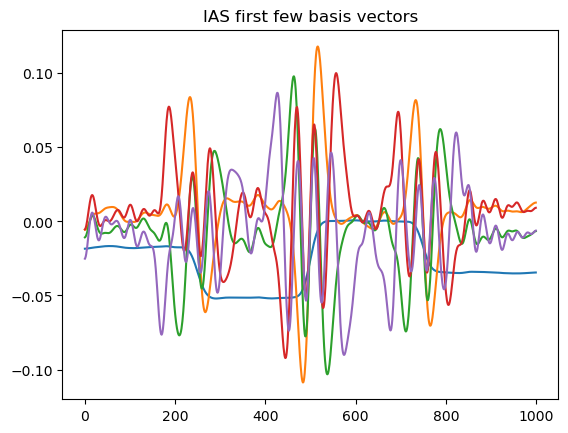

In [17]:
for j in range(5):
    plt.plot(ias_data["V"][:,j] )
plt.title("IAS first few basis vectors")
plt.show()

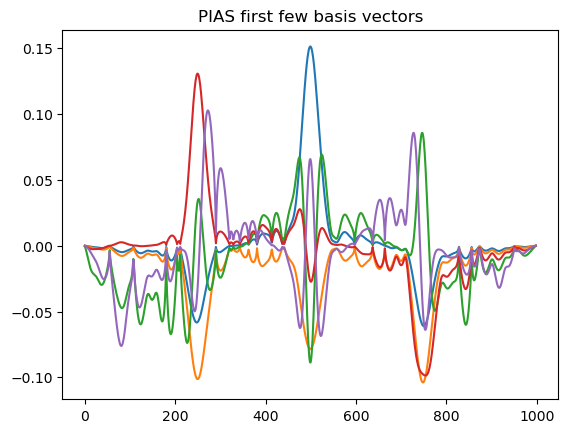

In [18]:
for j in range(5):
    plt.plot(pias_data[1]["V"][:,j] )
plt.title("PIAS first few basis vectors")
plt.show()

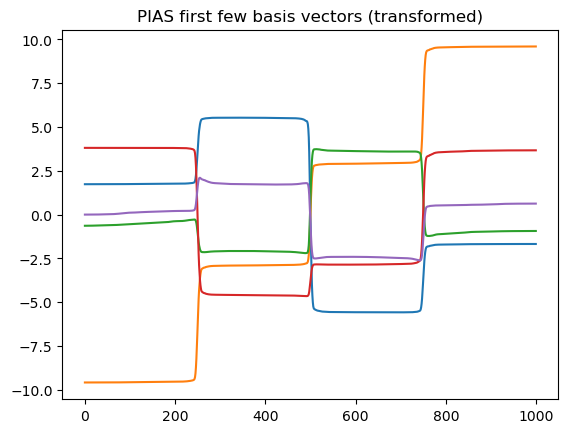

In [19]:
for j in range(5):
    plt.plot(pias_data[1]["LopinvV"][:,j] )
plt.title("PIAS first few basis vectors (transformed)")
plt.show()

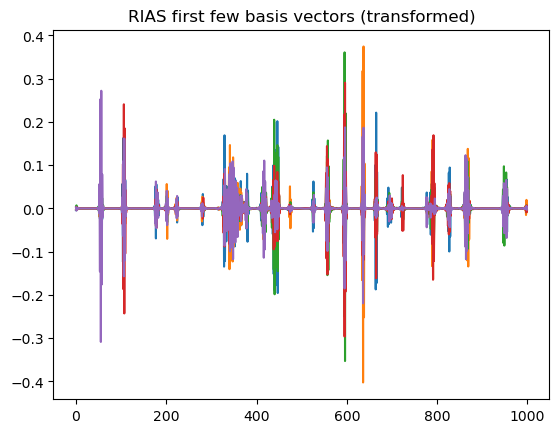

In [20]:
for j in range(5):
    plt.plot( rias_data["V"][:,j] )
plt.title("RIAS first few basis vectors (transformed)")
plt.show()